# Why Gauss–Legendre instead of Newton–Cotes?  

On the reference element $$-1\leq x\leq 1$$, a quadrature formula is

$$
\int_{-1}^{1}f(x)\,dx\approx\sum_{i=1}^{n}w_i f(x_i).
$$

| Rule | Integration points | Polynomial exactness with $$n$$ points |
|---|---|---|
| Closed Newton–Cotes | Equally spaced, **including endpoints** | Generally $$n-1$$; for odd $$n$$ the degree rises to $$n$$ by symmetry |
| Gauss–Legendre | Nonuniform roots of Legendre polynomial $$P_n$$ | $$2n-1$$ |

**Over three nodes:** Newton–Cotes integrates up to degree 3 exactly; 3-point Gauss–Legendre integrates up to degree 5 exactly.

For FEM stiffness integral,

$$
K_{ij}^{(e)}=\int_{x_a}^{x_b}\frac{dN_i}{dx}\frac{dN_j}{dx}\,dx,
$$

the integrand is a polynomial of degree at most $2p-2$ for a degree-$p$ Lagrange element with constant coefficients and mapping.

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import newton_cotes

# Match the simple Lagrange-basis function from our earlier FEM notebook.
def lagrange_basis(x, nodes, i):
    # Start the product with 1
    N = 1
    # Multiply all terms except j = i
    for j in range(len(nodes)):
        if j != i:
            N = N * (x - nodes[j]) / (nodes[i] - nodes[j])
    return N



## Oscillations from equally spaced Lagrange interpolation (Runge phenomenon)

Take the smooth function

$$
f(x)=\frac{1}{1+25x^2},\qquad -1\leq x\leq 1.
$$

Let's take single degree-16 Lagrange interpolant using **17 equally spaced nodes**. Compare it with interpolation at **17 Gauss–Legendre nodes**. Both use exactly 17 values of the function.

We evaluate the degree-16 interpolating polynomials directly using the `lagrange_basis(x, nodes, i)` function defined above.

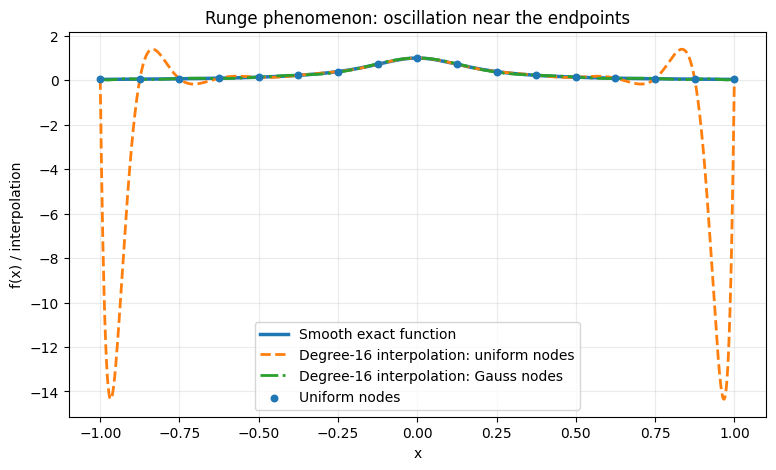

Max interpolation error (uniform): 14.392758
Max interpolation error (Gauss nodes): 0.062904


In [ ]:
def f(x):
    return 1.0 / (1.0 + 25.0*x**2)

n = 17
x_uniform = np.linspace(-1.0, 1.0, n)
x_gauss, w_gauss = np.polynomial.legendre.leggauss(n)

# Evaluate the interpolants using the Lagrange-basis function defined above.
x_plot = np.linspace(-1.0, 1.0, 1500)
y_exact = f(x_plot)
y_uniform = sum(f(x_uniform[i]) * lagrange_basis(x_plot, x_uniform, i) for i in range(n))
y_gauss = sum(f(x_gauss[i]) * lagrange_basis(x_plot, x_gauss, i) for i in range(n))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_plot, y_exact, lw=2.5, label="Smooth exact function")
ax.plot(x_plot, y_uniform, '--', lw=2, label="Degree-16 interpolation: uniform nodes")
ax.plot(x_plot, y_gauss, '-.', lw=2, label="Degree-16 interpolation: Gauss nodes")
ax.scatter(x_uniform, f(x_uniform), s=22, zorder=3, label="Uniform nodes")
ax.set(xlabel="x", ylabel="f(x) / interpolation", title="Runge phenomenon: oscillation near the endpoints")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print("Max interpolation error (uniform):",
      f"{np.max(np.abs(y_uniform-y_exact)):.6f}")
print("Max interpolation error (Gauss nodes):",
      f"{np.max(np.abs(y_gauss-y_exact)):.6f}")

For this function, the exact integral is known:
$$
I=\int_{-1}^{1}\frac{1}{1+25x^2}\,dx
=\frac{2}{5}\tan^{-1}(5).
$$
For a fair comparison, use exactly $n$ function evaluations in each rule. An $n$-point closed Newton–Cotes rule uses uniformly spaced points; an $n$-point Gauss–Legendre rule uses specially selected nonuniform points and weights.

Exact integral = 0.549360306778
 n | Newton-Cotes result | NC abs. error | Gauss result | Gauss abs. error
-------------------------------------------------------------------------------
 3 |         1.358974359 |    8.0961e-01 |  0.958333333 |    4.0897e-01
 5 |         0.474801061 |    7.4559e-02 |  0.706947920 |    1.5759e-01
 7 |         0.774089735 |    2.2473e-01 |  0.616122080 |    6.6762e-02
 9 |         0.300097781 |    2.4926e-01 |  0.578702697 |    2.9342e-02
11 |         0.934660111 |    3.8530e-01 |  0.562458112 |    1.3098e-02
13 |        -0.062587303 |    6.1195e-01 |  0.555246524 |    5.8862e-03
15 |         1.579908928 |    1.0305e+00 |  0.552013474 |    2.6532e-03
17 |        -1.248287463 |    1.7976e+00 |  0.550557759 |    1.1975e-03
19 |         3.775324258 |    3.2260e+00 |  0.549901056 |    5.4075e-04
21 |        -5.369910420 |    5.9193e+00 |  0.549604557 |    2.4425e-04


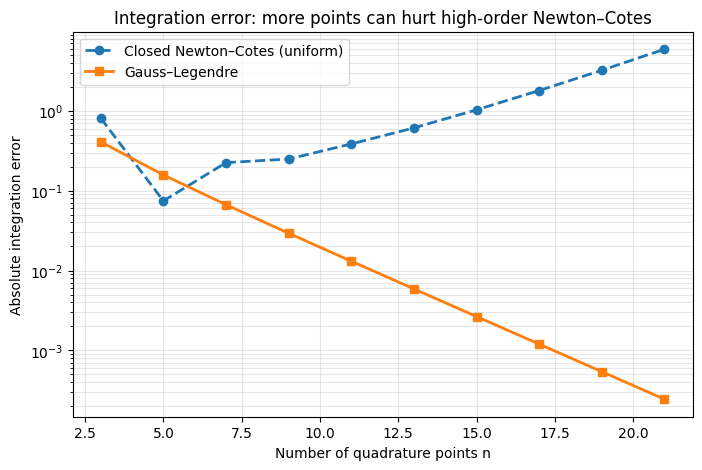

In [ ]:
def closed_newton_cotes(n, fun):
    """Integrate on [-1,1] using n equally spaced closed NC nodes."""
    x = np.linspace(-1.0, 1.0, n)
    weights, _ = newton_cotes(n-1, equal=1)
    weights = weights * (2.0 / (n-1))  # map weights to [-1,1]
    return np.dot(weights, fun(x)), x, weights

def gauss_legendre(n, fun):
    """Integrate on [-1,1] using n Gauss–Legendre nodes."""
    x, weights = np.polynomial.legendre.leggauss(n)
    return np.dot(weights, fun(x)), x, weights

I_exact = 2.0 * np.arctan(5.0) / 5.0
n_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
nc_errors, gl_errors = [], []

print(f"Exact integral = {I_exact:.12f}")
print(" n | Newton-Cotes result | NC abs. error | Gauss result | Gauss abs. error")
print("-"*79)
for n in n_values:
    I_nc, _, _ = closed_newton_cotes(n, f)
    I_gl, _, _ = gauss_legendre(n, f)
    en, eg = abs(I_nc - I_exact), abs(I_gl - I_exact)
    nc_errors.append(en)
    gl_errors.append(eg)
    print(f"{n:2d} | {I_nc:19.9f} | {en:13.4e} | {I_gl:12.9f} | {eg:13.4e}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(n_values, nc_errors, 'o--', lw=2, label="Closed Newton–Cotes (uniform)")
ax.semilogy(n_values, gl_errors, 's-', lw=2, label="Gauss–Legendre")
ax.set(xlabel="Number of quadrature points n", ylabel="Absolute integration error",
       title="Integration error: more points can hurt high-order Newton–Cotes")
ax.grid(alpha=0.3, which='both')
ax.legend()
plt.show()

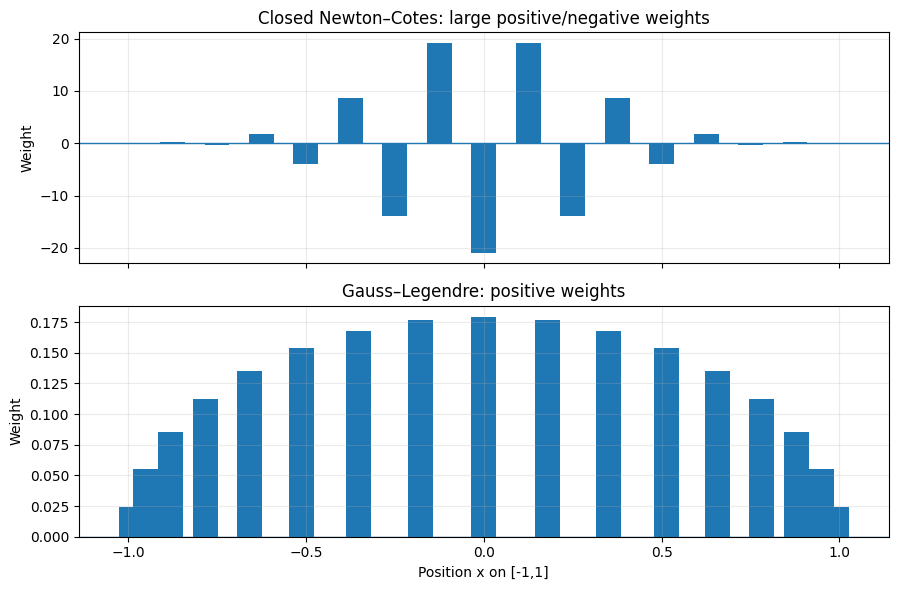

For n=17: Newton–Cotes has 7 negative weights
Gauss–Legendre has 0 negative weights
Largest |Newton–Cotes weight| = 20.9520
Largest |Gauss weight|        = 0.1794


In [ ]:
n = 17
_, x_nc, w_nc = closed_newton_cotes(n, f)
_, x_gl, w_gl = gauss_legendre(n, f)

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].bar(x_nc, w_nc, width=0.07)
axes[0].axhline(0, lw=1)
axes[0].set(ylabel="Weight", title="Closed Newton–Cotes: large positive/negative weights")
axes[0].grid(alpha=0.25)

axes[1].bar(x_gl, w_gl, width=0.07)
axes[1].axhline(0, lw=1)
axes[1].set(xlabel="Position x on [-1,1]", ylabel="Weight",
            title="Gauss–Legendre: positive weights")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"For n={n}: Newton–Cotes has {np.count_nonzero(w_nc < 0)} negative weights")
print(f"Gauss–Legendre has {np.count_nonzero(w_gl < 0)} negative weights")
print(f"Largest |Newton–Cotes weight| = {np.max(np.abs(w_nc)):.4f}")
print(f"Largest |Gauss weight|        = {np.max(np.abs(w_gl)):.4f}")